In [1]:
import ee
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

# Initialize Earth Engine with your non-commercial Cloud Project ID
PROJECT_ID = 'satellite-economic-nowcasting'

try:
    ee.Initialize(project=PROJECT_ID)
    print("✓ Google Earth Engine initialized successfully.")
except Exception as e:
    print(f"Initialization failed: {e}")

✓ Google Earth Engine initialized successfully.


In [2]:
# 1. Define Point of Interest (Lagos, Nigeria)
poi = ee.Geometry.Point([3.3792, 6.5244])

# 2. Query USGS Landsat 8 Level-2 Tier 1 Collection
# Bands: SR_B4 (Red), SR_B3 (Green), SR_B2 (Blue)
collection = (
    ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    .filterBounds(poi)
    .filterDate('2023-01-01', '2023-12-31')
    .sort('CLOUD_COVER')
)

# Extract least cloudy scene
first_image = collection.first()

# Extract metadata
metadata = first_image.getInfo()
image_id = metadata['id']
cloud_cover = metadata['properties']['CLOUD_COVER']
date_acquired = metadata['properties']['DATE_ACQUIRED']

print(f"Selected Scene ID : {image_id}")
print(f"Date Acquired     : {date_acquired}")
print(f"Cloud Cover       : {cloud_cover:.2f}%")

Selected Scene ID : LANDSAT/LC08/C02/T1_L2/LC08_191056_20231214
Date Acquired     : 2023-12-14
Cloud Cover       : 0.01%


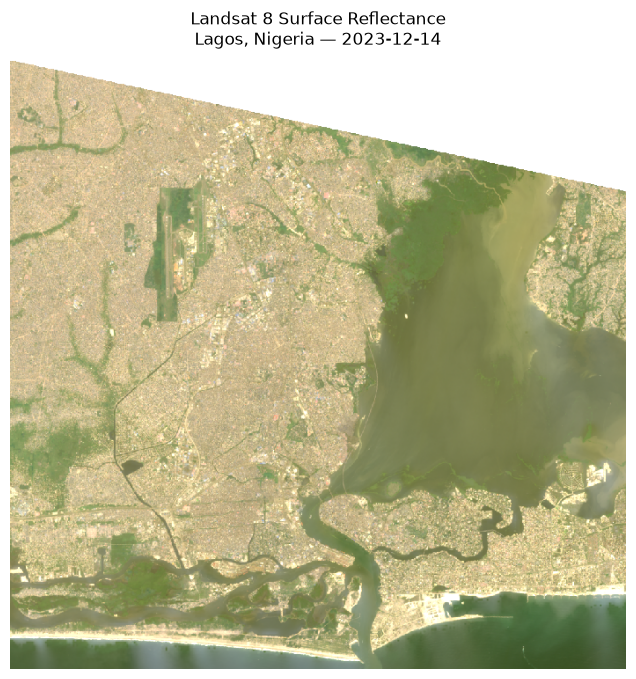

✓ Satellite image successfully saved to: ../docs/first_satellite_image.png


In [3]:
# 1. Create a 15 km bounding box around the center coordinate
roi = poi.buffer(15000).bounds()

# 2. Landsat 8 Surface Reflectance visual range (7000 to 13000 raw DN)
vis_params = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 7000,
    'max': 13000,
    'gamma': 1.4,
    'region': roi.getInfo(),
    'dimensions': 700,
    'format': 'png'
}

# 3. Retrieve thumbnail URL directly from GEE
thumb_url = first_image.getThumbURL(vis_params)

# 4. Download and save locally for documentation
output_path = '../docs/first_satellite_image.png'
urllib.request.urlretrieve(thumb_url, output_path)

# 5. Display the satellite image
img = Image.open(output_path)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title(f"Landsat 8 Surface Reflectance\nLagos, Nigeria — {date_acquired}", fontsize=12)
plt.axis('off')
plt.show()

print(f"✓ Satellite image successfully saved to: {output_path}")

In [4]:
# List available spectral bands in this collection
bands = [b['id'] for b in metadata['bands']]
print("Available Bands in Scene:")
for b in bands:
    if b.startswith('SR_'):
        print(f" - {b}")

Available Bands in Scene:
 - SR_B1
 - SR_B2
 - SR_B3
 - SR_B4
 - SR_B5
 - SR_B6
 - SR_B7
 - SR_QA_AEROSOL
